# Closed-loop docking: the whole chain in one simulation

Every notebook so far has validated one model on its own: a relative trajectory flown without sensors, an attitude controller pointing at a target chosen in advance, a filter fed with synthetic measurements. This notebook puts all of them in the same loop and flies the reference mission from a hold point 5 km behind the chief to the contact of the two docking ports.

The loop is the one a real spacecraft runs. Sensors observe the true state with their errors. The navigation turns those measurements into estimates of attitude and relative position. The guidance decides, from the estimates only, where the deputy should go and where it should point. The controllers turn that into a force and a torque. The actuators deliver them as well as their limits allow. The truth model, a nonlinear propagation of both spacecraft with $J_2$, drag and the full attitude dynamics of the deputy, then advances by one second under the force and torque actually produced, and the cycle repeats.

Nothing in the on-board chain has access to the true state. The question the simulation answers is therefore the one that matters for a mission: whether the estimates, the commands and the hardware, with all their imperfections acting at the same time, bring the two ports together inside the limits that the docking mechanism accepts.

In [1]:
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

from ios_mission_planner.gnc.mission_manager import Phase, PHASE_LABELS
from ios_mission_planner.sim.config import SimulationConfig
from ios_mission_planner.sim.simulator import simulate

mpl.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
})

COL_ANA = "#1f77b4"
COL_NUM = "#d62728"
COL_ZONE = "#9467bd"

PHASE_COLORS = {
    Phase.HOLD_FAR: "#7f7f7f", Phase.TRANSFER: "#1f77b4", Phase.HOLD_MID: "#7f7f7f",
    Phase.APPROACH: "#ff7f0e", Phase.HOLD_NEAR: "#7f7f7f", Phase.FINAL_APPROACH: "#d62728",
    Phase.DOCKED: "#2ca02c", Phase.ABORT: "#9467bd",
}


def shade_phases(ax, result):
    """Light vertical bands for the transfer, the forced approach and the final approach."""
    for phase in (Phase.TRANSFER, Phase.APPROACH, Phase.FINAL_APPROACH, Phase.ABORT):
        mask = result.phase == phase
        if mask.any():
            ax.axvspan(result.t[mask][0] / 60, result.t[mask][-1] / 60, color=PHASE_COLORS[phase], alpha=0.08, lw=0)

## The scenario

`SimulationConfig` collects every number that defines a scenario, with defaults that describe the reference mission. The chief flies at 500 km and 51.6 degrees of inclination, holds its attitude fixed in its own LVLH frame and carries a docking port on its rear face, looking backward along the V-bar. The deputy is a 160 kg servicer with on-off thrusters of 2 N on each body axis, a minimum impulse bit of 0.04 N s, and three reaction wheels of 0.02 N m and 0.5 N m s. It carries a gyro, a star tracker and a relative sensor that measures range and direction of a target next to the port of the chief, with an error that grows with the distance.

The approach profile has three hold points on the V-bar, at 5 km, 500 m and 20 m between the ports, called S1, S2 and S3. The values are representative of a small servicer; they are inputs, and a study of a specific vehicle replaces them with its own.

In [2]:
config = SimulationConfig(seed=1)

n = np.sqrt(config.environment.mu / (config.environment.r_eq + config.chief.altitude_km) ** 3)
print(f"orbital period of the chief: {2 * np.pi / n / 60:.1f} min")
print(f"acceleration available per axis: {config.deputy.thrusters.max_force / config.deputy.mass * 1e3:.1f} mm/s^2")
print(f"smallest velocity change of one pulse: "
      f"{config.deputy.thrusters.min_impulse_bit / config.deputy.mass * 1e3:.2f} mm/s")
print(f"true initial offset from S1: {np.linalg.norm(config.initial.position_offset):.0f} m, "
      f"error of the first navigation estimate: {np.linalg.norm(config.initial.navigation_position_error):.0f} m")

result = simulate(config)

print(f"\noutcome: {result.outcome} after {result.duration / 60:.1f} min, "
      f"{result.total_delta_v:.2f} m/s, {result.propellant_used * 1e3:.0f} g of propellant\n")
for time, label, note in result.events:
    print(f"{time / 60:7.1f} min   {label:26s} {note}")

orbital period of the chief: 94.6 min
acceleration available per axis: 12.5 mm/s^2
smallest velocity change of one pulse: 0.25 mm/s
true initial offset from S1: 39 m, error of the first navigation estimate: 35 m



outcome: docked after 96.0 min, 6.06 m/s, 449 g of propellant

    5.0 min   transfer S1 to S2          departure burn 1.543 m/s
   17.8 min   transfer S1 to S2          correction burn 0.051 m/s
   30.6 min   transfer S1 to S2          correction burn 0.010 m/s
   41.2 min   transfer S1 to S2          correction burn 0.030 m/s
   46.5 min   transfer S1 to S2          arrival burn 1.603 m/s
   48.6 min   hold at S2                 
   53.6 min   forced approach S2 to S3   
   89.2 min   hold at S3                 
   91.2 min   final approach             
   96.0 min   docked                     


## The approach as flown

The first plot is the true relative trajectory in the orbit plane, with the chief at the origin and the direction of flight to the right. The second enlarges the last 25 m, with the approach corridor that the predictive controller is asked to respect.

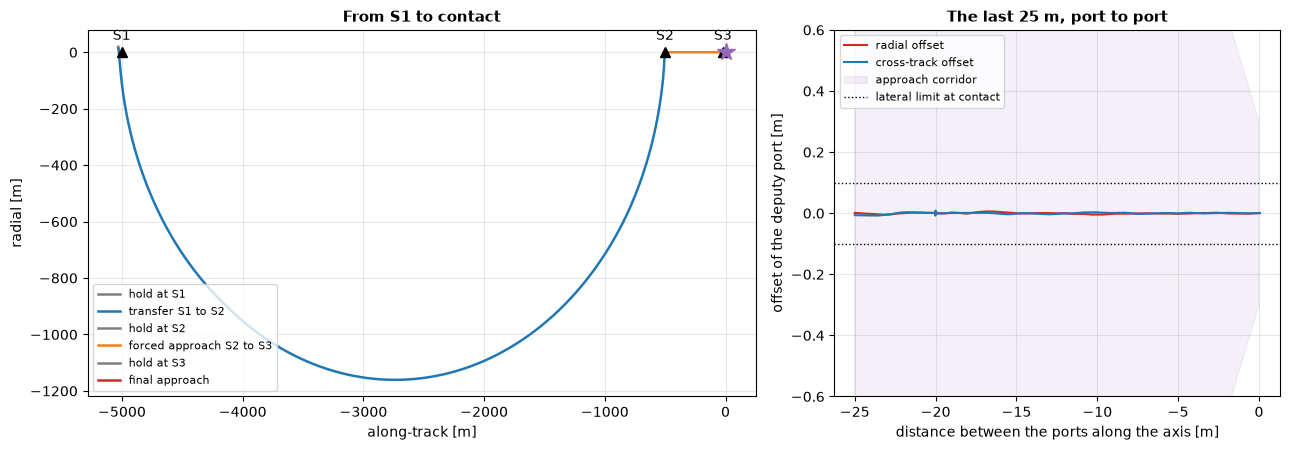

In [3]:
x = result.relative_state
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.5, 1]})

ax = axes[0]
for phase in Phase:
    mask = result.phase == phase
    if mask.any() and phase != Phase.DOCKED:
        ax.plot(x[mask, 1], x[mask, 0], color=PHASE_COLORS[phase], lw=1.8, label=PHASE_LABELS[phase])
for name, point in zip(("S1", "S2", "S3"), result.hold_positions):
    ax.plot(point[1], point[0], "k^", ms=7)
    ax.annotate(name, (point[1], point[0]), textcoords="offset points", xytext=(0, 9), ha="center")
ax.plot(0, 0, "*", color=COL_ZONE, ms=13)
ax.set_xlabel("along-track [m]"); ax.set_ylabel("radial [m]")
ax.set_title("From S1 to contact")
handles, labels = ax.get_legend_handles_labels()
unique = dict(zip(labels, handles))
ax.legend(unique.values(), unique.keys(), fontsize=8, loc="lower left")

ax = axes[1]
near = result.port_axial < 25.0
ax.plot(-result.port_axial[near], result.port_lateral[near, 0], color=COL_NUM, lw=1.5, label="radial offset")
ax.plot(-result.port_axial[near], result.port_lateral[near, 1], color=COL_ANA, lw=1.5, label="cross-track offset")
d = np.linspace(0, 25, 50)
g = config.guidance
edge = g.corridor_radius + np.tan(np.deg2rad(g.corridor_half_angle_deg)) * d
ax.fill_between(-d, -edge, edge, color=COL_ZONE, alpha=0.10, label="approach corridor")
ax.axhline(config.docking_limits.lateral_misalignment, color="k", ls=":", lw=1)
ax.axhline(-config.docking_limits.lateral_misalignment, color="k", ls=":", lw=1, label="lateral limit at contact")
ax.set_ylim(-0.6, 0.6)
ax.set_xlabel("distance between the ports along the axis [m]"); ax.set_ylabel("offset of the deputy port [m]")
ax.set_title("The last 25 m, port to port")
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()

The shape of each leg tells which law flew it. The transfer from S1 to S2 is a natural arc: two burns, a coast of 0.45 orbits in between, and three small corrections on the way. The forced approach from S2 to S3 is a straight line along the V-bar, which is not a natural motion and has to be held by the thrusters continuously. In the last metres the offset of the port from the axis stays a small fraction of the limit that the mechanism accepts.

## Navigation

The guidance only ever sees the navigation estimate, so the first thing to check is how far that estimate is from the truth, and whether the filter knows it. The plot compares the actual error of the estimated relative position with the three-sigma bound computed by the filter itself, on a logarithmic scale because both change by four orders of magnitude along the approach.

fraction of samples inside 3 sigma: 98.9 %
hold at S1       position error (rms)   2.7774 m, velocity error (rms)  21.762 mm/s
hold at S2       position error (rms)   0.1758 m, velocity error (rms)   1.738 mm/s
hold at S3       position error (rms)   0.0124 m, velocity error (rms)   0.213 mm/s
final approach   position error (rms)   0.0119 m, velocity error (rms)   0.190 mm/s


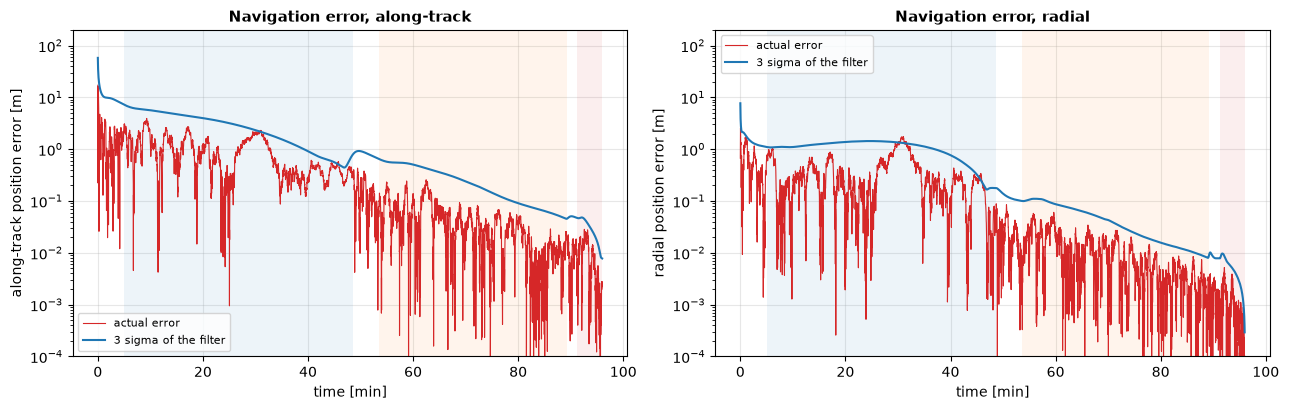

In [4]:
error = np.abs(result.relative_state - result.relative_estimate)
t_min = result.t / 60

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, index, name in ((axes[0], 1, "along-track"), (axes[1], 0, "radial")):
    ax.semilogy(t_min, np.maximum(error[:, index], 1e-5), color=COL_NUM, lw=0.8, label="actual error")
    ax.semilogy(t_min, 3 * result.relative_std[:, index], color=COL_ANA, lw=1.5, label="3 sigma of the filter")
    shade_phases(ax, result)
    ax.set_xlabel("time [min]"); ax.set_ylabel(f"{name} position error [m]")
    ax.set_title(f"Navigation error, {name}")
    ax.set_ylim(1e-4, 200)
    ax.legend(fontsize=8)
fig.tight_layout()

inside = (error <= 3 * result.relative_std).mean()
print(f"fraction of samples inside 3 sigma: {inside * 100:.1f} %")
for phase in (Phase.HOLD_FAR, Phase.HOLD_MID, Phase.HOLD_NEAR, Phase.FINAL_APPROACH):
    mask = result.phase == phase
    print(f"{PHASE_LABELS[phase]:16s} position error (rms) {np.sqrt((error[mask, :3] ** 2).sum(axis=1).mean()):8.4f} m, "
          f"velocity error (rms) {np.sqrt((error[mask, 3:] ** 2).sum(axis=1).mean()) * 1e3:7.3f} mm/s")

The estimate starts tens of metres wrong and converges during the hold at S1, which is what that hold is for. From there the error follows the bound down as the deputy closes in, because the sensor measures range to a fraction of the distance and direction to a fixed angle: both become smaller in metres as the distance shrinks. The navigation is accurate exactly where the mission needs it, at the port, and coarse where it can afford to be.

The bound is honest. The error stays inside three sigma almost everywhere, including during the transfer, where the linear model used by the filter is at its worst. This required telling the filter how wrong its model is: at 5 km the terms that the Clohessy-Wiltshire equations neglect are larger than any perturbation, and without a process noise that grows with the square of the distance the filter becomes overconfident and its error leaves the bound for a third of the transfer.

## Guidance and control

The next plots show the distance between the ports and the closing speed, with the limit on the closing speed that the predictive controller enforces, the force actually delivered by the thrusters on each body axis, and the velocity change spent in each phase.

forced approach: 2.05 m/s, of which 2 n d = 1.06 m/s only to stay on the V-bar, plus speeding up and stopping at 0.4 m/s


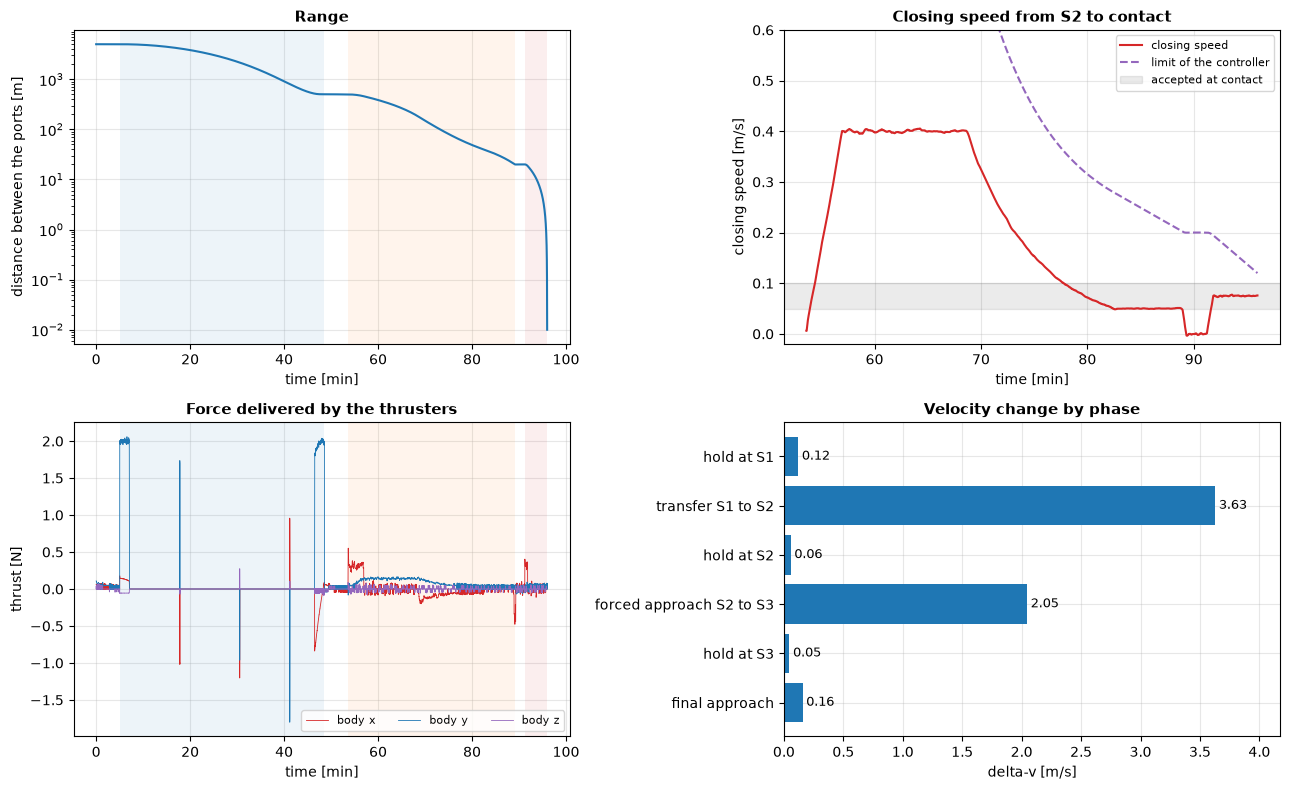

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

ax = axes[0, 0]
ax.semilogy(t_min, np.maximum(result.port_axial, 1e-2), color=COL_ANA)
shade_phases(ax, result)
ax.set_xlabel("time [min]"); ax.set_ylabel("distance between the ports [m]")
ax.set_title("Range")

ax = axes[0, 1]
late = result.phase >= Phase.APPROACH
limit = g.closing_speed_floor + g.closing_speed_slope * np.maximum(result.port_axial, 0)
ax.plot(t_min[late], result.port_closing_speed[late], color=COL_NUM, label="closing speed")
ax.plot(t_min[late], np.minimum(limit[late], 0.6), color=COL_ZONE, ls="--", label="limit of the controller")
ax.axhspan(config.docking_limits.axial_speed_min, config.docking_limits.axial_speed_max, color="k", alpha=0.08,
           label="accepted at contact")
ax.set_ylim(-0.02, 0.6)
ax.set_xlabel("time [min]"); ax.set_ylabel("closing speed [m/s]")
ax.set_title("Closing speed from S2 to contact")
ax.legend(fontsize=8)

ax = axes[1, 0]
for index, (name, color) in enumerate((("body x", COL_NUM), ("body y", COL_ANA), ("body z", COL_ZONE))):
    ax.plot(t_min, result.thrust[:, index], color=color, lw=0.6, label=name)
shade_phases(ax, result)
ax.set_xlabel("time [min]"); ax.set_ylabel("thrust [N]")
ax.set_title("Force delivered by the thrusters")
ax.legend(fontsize=8, ncol=3)

ax = axes[1, 1]
spent = {k: v for k, v in result.delta_v_by_phase().items() if k != "docked"}
ax.barh(list(spent), list(spent.values()), color=COL_ANA)
for k, (label, value) in enumerate(spent.items()):
    ax.text(value + 0.03, k, f"{value:.2f}", va="center", fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, max(spent.values()) * 1.15)
ax.set_xlabel("delta-v [m/s]")
ax.set_title("Velocity change by phase")
fig.tight_layout()

distance = g.hold_distances[1] - g.hold_distances[2]
print(f"forced approach: {spent['forced approach S2 to S3']:.2f} m/s, of which 2 n d = {2 * n * distance:.2f} m/s "
      f"only to stay on the V-bar, plus speeding up and stopping at {g.approach_v_max} m/s")

Two phases take almost all the propellant, for different reasons. The transfer is expensive because it is fast: covering 4.5 km in less than half an orbit takes two burns of about 1.5 m/s each, while a transfer over a full orbit with tangential burns would cost a sixth of that and take twice as long. The forced approach is expensive because it is straight. A deputy moving along the V-bar at speed $v$ feels a Coriolis acceleration $2nv$ that pushes it off the line, and cancelling it over a distance $d$ costs $2nd$ whatever the speed: about 1 m/s for the 480 m from S2 to S3, to which the acceleration and the braking add twice the cruise speed. The closing speed follows the glideslope law, proportional to the distance to go, stays well below the limit imposed on the controller, and settles on the docking speed for the last 20 m.

The force plot shows the average force over each one-second step: full thrust for the two burns of the transfer, short spikes for the corrections, and a small average force, made of short pulses, when the controller asks for a continuous push during the forced approach.

## Attitude

The attitude loop runs at the same time, and the translation depends on it twice: the thrust goes where the body points, and the relative sensor only sees the chief while the chief is in its field of view.

pointing error after the first 5 min: max 0.236 deg
knowledge error after the first 5 min: max 29 arcsec
largest wheel momentum: 0.086 N m s (17 % of the limit)


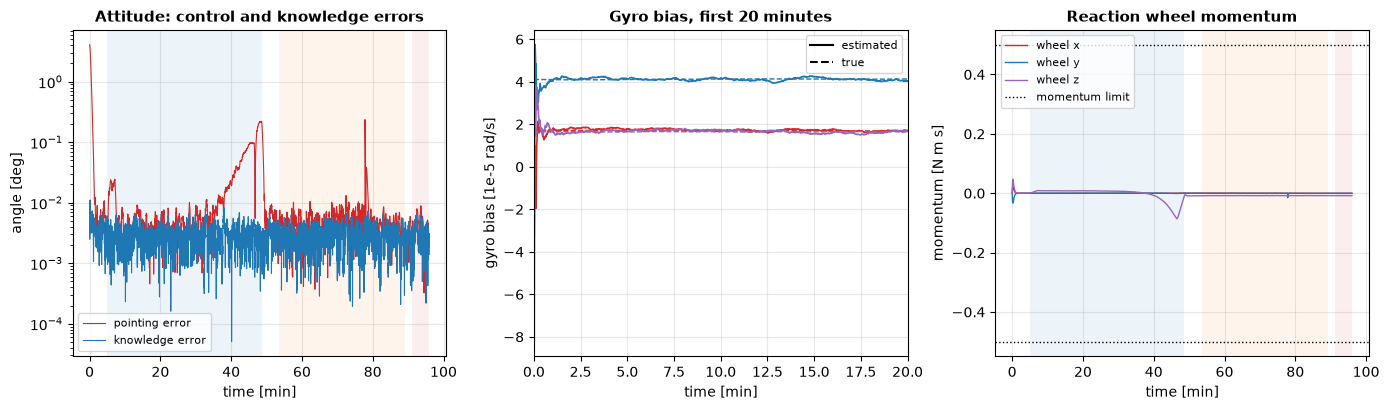

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))

ax = axes[0]
ax.semilogy(t_min, np.degrees(np.maximum(result.attitude_error, 1e-9)), color=COL_NUM, lw=0.8, label="pointing error")
ax.semilogy(t_min, np.degrees(np.maximum(result.attitude_knowledge_error, 1e-9)), color=COL_ANA, lw=0.8,
            label="knowledge error")
shade_phases(ax, result)
ax.set_xlabel("time [min]"); ax.set_ylabel("angle [deg]")
ax.set_title("Attitude: control and knowledge errors")
ax.legend(fontsize=8)

ax = axes[1]
for index, color in enumerate((COL_NUM, COL_ANA, COL_ZONE)):
    ax.plot(t_min, result.gyro_bias_estimate[:, index] * 1e5, color=color, lw=1.2)
    ax.plot(t_min, result.gyro_bias[:, index] * 1e5, color=color, lw=1.0, ls="--")
ax.plot([], [], "k-", label="estimated"); ax.plot([], [], "k--", label="true")
ax.set_xlim(0, 20)
ax.set_xlabel("time [min]"); ax.set_ylabel("gyro bias [1e-5 rad/s]")
ax.set_title("Gyro bias, first 20 minutes")
ax.legend(fontsize=8)

ax = axes[2]
for index, (name, color) in enumerate((("x", COL_NUM), ("y", COL_ANA), ("z", COL_ZONE))):
    ax.plot(t_min, result.wheel_momentum[:, index], color=color, lw=1.0, label=f"wheel {name}")
ax.axhline(config.deputy.wheels.max_momentum, color="k", ls=":", lw=1)
ax.axhline(-config.deputy.wheels.max_momentum, color="k", ls=":", lw=1, label="momentum limit")
shade_phases(ax, result)
ax.set_xlabel("time [min]"); ax.set_ylabel("momentum [N m s]")
ax.set_title("Reaction wheel momentum")
ax.legend(fontsize=8)
fig.tight_layout()

after = result.t > 300
print(f"pointing error after the first 5 min: max {np.degrees(result.attitude_error[after]).max():.3f} deg")
print(f"knowledge error after the first 5 min: max {np.degrees(result.attitude_knowledge_error[after]).max() * 3600:.0f} arcsec")
print(f"largest wheel momentum: {np.abs(result.wheel_momentum).max():.3f} N m s "
      f"({np.abs(result.wheel_momentum).max() / config.deputy.wheels.max_momentum * 100:.0f} % of the limit)")

The deputy starts a few degrees away from the commanded attitude and removes the error at the limited slew rate. From then on the pointing error stays at a fraction of a degree while the deputy tracks a chief whose direction keeps changing, and falls by another order of magnitude once the command becomes the fixed alignment of the two ports. The command is built in the inertial frame, so it contains the rotation of once per orbit that a spacecraft facing the chief must follow, and the controller receives the rate of the command together with the command: this is why there is no steady lag, unlike in the pointing notebook, where the command was held between updates.

The filter estimates the gyro bias within a few minutes, and the attitude knowledge error stays at the level of the star tracker. The wheels use a small part of their capacity. That is true here because the thrusters are assumed balanced, an assumption examined at the end of this notebook.

## Contact

The simulation ends when the port of the deputy crosses the plane of the port of the chief. The state of the two ports at that instant is compared with the conditions that the docking mechanism accepts. The limits used here are representative of the initial contact conditions of the International Docking System Standard; they are scenario parameters, and those of a real mechanism come from its interface definition.

condition                           value   limit
lateral misalignment [m]           0.0006   below 0.1        ok
axial speed [m/s]                  0.0758   0.05 to 0.1      ok
lateral speed [m/s]                0.0001   below 0.04       ok
angular misalignment [deg]         0.0016   below 4.0        ok
roll misalignment [deg]            0.0018   below 4.0        ok
angular rate [deg/s]               0.0002   below 0.2        ok


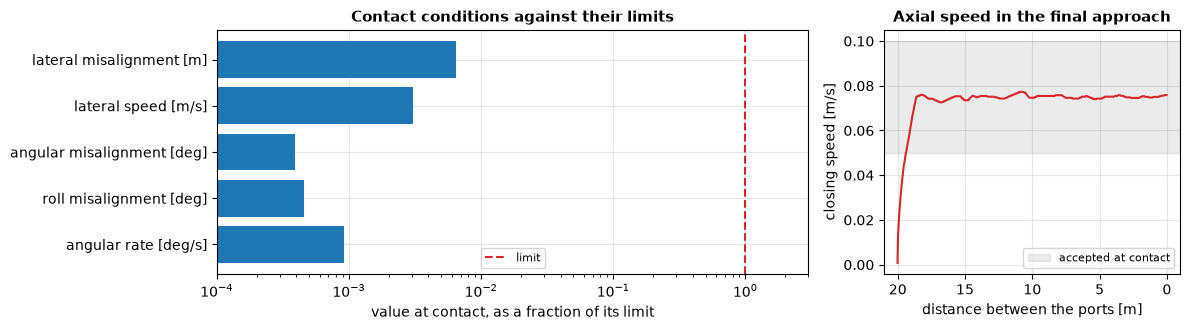

In [7]:
contact = result.contact
print(f"{'condition':30s} {'value':>10s}   limit")
for name, value in contact.values.items():
    bound = contact.limits[name]
    text = f"{bound[0]} to {bound[1]}" if isinstance(bound, tuple) else f"below {bound}"
    print(f"{name:30s} {value:10.4f}   {text:16s} {'ok' if contact.passed[name] else 'VIOLATED'}")

names = [k for k in contact.values if k != "axial speed [m/s]"]
ratios = [contact.values[k] / contact.limits[k] for k in names]
low, high = contact.limits["axial speed [m/s]"]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), gridspec_kw={"width_ratios": [2, 1]})
axes[0].barh(names, ratios, color=COL_ANA)
axes[0].axvline(1.0, color=COL_NUM, ls="--", label="limit")
axes[0].set_xscale("log"); axes[0].set_xlim(1e-4, 3)
axes[0].invert_yaxis()
axes[0].set_xlabel("value at contact, as a fraction of its limit")
axes[0].set_title("Contact conditions against their limits")
axes[0].legend(fontsize=8)

final = result.phase == Phase.FINAL_APPROACH
axes[1].plot(result.port_axial[final], result.port_closing_speed[final], color=COL_NUM)
axes[1].axhspan(low, high, color="k", alpha=0.08, label="accepted at contact")
axes[1].invert_xaxis()
axes[1].set_xlabel("distance between the ports [m]"); axes[1].set_ylabel("closing speed [m/s]")
axes[1].set_title("Axial speed in the final approach")
axes[1].legend(fontsize=8)
fig.tight_layout()

Every condition is met, most of them with a margin of one or two orders of magnitude. The only one that is not a "smaller is better" quantity is the axial speed, which must be high enough for the mechanism to capture and low enough not to damage it: the controller holds it in the middle of its band.

A single run with nominal hardware is the best case. How these margins hold when the thrusters are misaligned, the sensor is mounted with an error and the chief is not exactly where it should be is the subject of the Monte Carlo notebook.

## What the mid-course corrections are for

The transfer is planned with the linear model and flown in the nonlinear one, with thrusters that take about two minutes to deliver each burn. The three corrections on the way are small, and it is fair to ask whether they are needed. Flying the same mission without them answers the question.

In [8]:
def arrival_error(run):
    """Distance from S2 at the moment the hold at S2 begins."""
    k = np.argmax(run.phase == Phase.HOLD_MID)
    return np.linalg.norm(run.relative_state[k, :3] - run.hold_positions[1])

no_corrections = SimulationConfig(seed=1)
no_corrections.guidance.correction_fractions = ()
uncorrected = simulate(no_corrections)

for name, run in (("with corrections", result), ("without corrections", uncorrected)):
    spent = run.delta_v_by_phase()
    print(f"{name:20s} arrival {arrival_error(run):6.1f} m from S2, transfer {spent['transfer S1 to S2']:.3f} m/s, "
          f"hold at S2 {spent['hold at S2']:.3f} m/s, outcome: {run.outcome}")

with corrections     arrival    4.7 m from S2, transfer 3.629 m/s, hold at S2 0.058 m/s, outcome: docked
without corrections  arrival  167.8 m from S2, transfer 3.456 m/s, hold at S2 1.779 m/s, outcome: docked


Without corrections the deputy arrives more than 150 m from S2 instead of 5 m. The mission still succeeds, because the hold at S2 brings the deputy back, but the error is paid there: the hold costs 1.8 m/s instead of 0.06 m/s. The three corrections together cost less than 0.1 m/s and remove the error early, when it is cheap to do so. This is the same residual that the rendezvous notebook found when it flew a transfer designed with the linear model in the nonlinear dynamics; here it is corrected in flight instead of being measured afterward.

## When something fails

A simulation of the nominal mission says little about safety. The mission manager watches a set of conditions during the approach (position inside the corridor, closing speed, availability of the relative measurements, navigation uncertainty, attitude error) and, when one of them is violated, abandons the approach with a collision avoidance maneuver: a burn of 0.5 m/s away from the chief along the port axis.

The first failure injected is the loss of the relative sensor during the final approach, with the ports 9 m apart.

outcome: aborted (relative measurements lost)
sensor lost with the ports 9.4 m apart, maneuver started 30 s later, at 7.1 m
closest distance between the centers of mass after the maneuver: 8.5 m


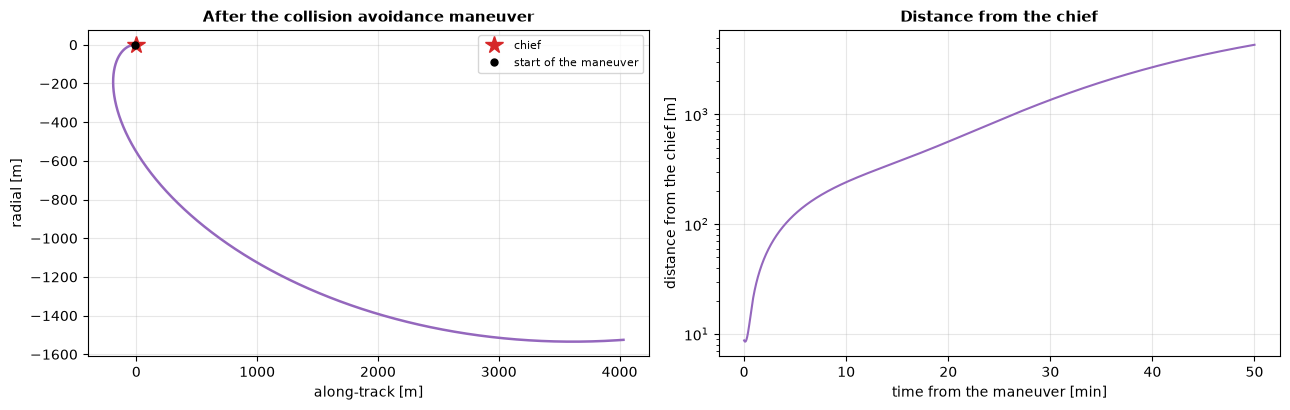

In [9]:
failed = SimulationConfig(seed=1)
start_final = next(time for time, label, _ in result.events if label == "final approach")
failed.failures.sensor_outage_start = start_final + 160.0
failed.failures.sensor_outage_duration = 1e5
failed.guidance.abort_coast_duration = 3000.0
aborted = simulate(failed)

k_abort = np.argmax(aborted.phase == Phase.ABORT)
print(f"outcome: {aborted.outcome} ({aborted.abort_reason})")
print(f"sensor lost with the ports {aborted.port_axial[np.searchsorted(aborted.t, failed.failures.sensor_outage_start)]:.1f} m apart, "
      f"maneuver started {aborted.t[k_abort] - failed.failures.sensor_outage_start:.0f} s later, at {aborted.port_axial[k_abort]:.1f} m")
distance = np.linalg.norm(aborted.relative_state[:, :3], axis=1)
print(f"closest distance between the centers of mass after the maneuver: {distance[k_abort:].min():.1f} m")

xa = aborted.relative_state
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
after = aborted.phase == Phase.ABORT
axes[0].plot(xa[after, 1], xa[after, 0], color=PHASE_COLORS[Phase.ABORT], lw=1.8)
axes[0].plot(0, 0, "*", color=COL_NUM, ms=13, label="chief")
axes[0].plot(xa[k_abort, 1], xa[k_abort, 0], "ko", ms=5, label="start of the maneuver")
axes[0].set_xlabel("along-track [m]"); axes[0].set_ylabel("radial [m]")
axes[0].set_title("After the collision avoidance maneuver")
axes[0].legend(fontsize=8)

minutes = (aborted.t - aborted.t[k_abort]) / 60
axes[1].semilogy(minutes[after], distance[after], color=PHASE_COLORS[Phase.ABORT])
axes[1].set_xlabel("time from the maneuver [min]"); axes[1].set_ylabel("distance from the chief [m]")
axes[1].set_title("Distance from the chief")
fig.tight_layout()

Thirty seconds without measurements trigger the maneuver. A retrograde burn puts the deputy on a slightly lower orbit: it first falls back and down, then, being lower and therefore faster, it overtakes the chief from below at a distance of hundreds of metres and keeps drifting ahead. The deputy closes another 20 cm while the burn reverses its velocity, and from then on it only moves away. The trajectory after the burn needs no further thrust and no navigation to stay safe, which is the property that the safety chapter called passive safety, here obtained on purpose.

The second failure is not a broken component but an assumption. The thrusters have been taken as balanced, with thrust lines passing exactly through the center of mass. If the center of mass is a few millimetres away from where it was assumed, every firing produces a small torque that the wheels must absorb.

no momentum management               outcome: aborted  reason: relative measurements lost, largest attitude error 180.0 deg, propellant 381 g
thruster couples unload the wheels   outcome: docked   reason: None, largest attitude error 3.0 deg, propellant 461 g


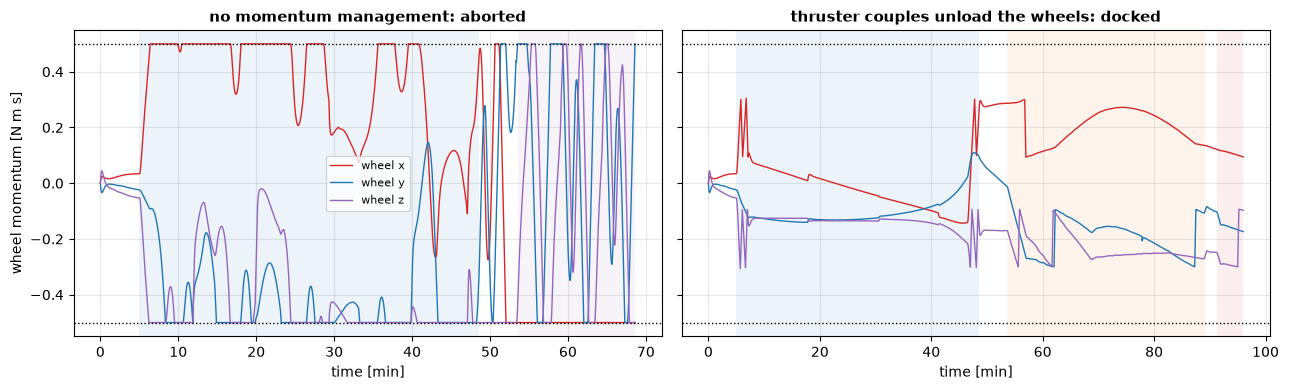

In [10]:
offset = np.array([0.003, -0.003, 0.003])
runs = {}
for name, managed in (("no momentum management", False), ("thruster couples unload the wheels", True)):
    case = SimulationConfig(seed=1)
    case.deputy.thrusters.center_of_mass_offset = offset
    case.deputy.wheels.desaturation_enabled = managed
    runs[name] = simulate(case)

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, (name, run) in zip(axes, runs.items()):
    for index, (axis_name, color) in enumerate((("x", COL_NUM), ("y", COL_ANA), ("z", COL_ZONE))):
        ax.plot(run.t / 60, run.wheel_momentum[:, index], color=color, lw=1.0, label=f"wheel {axis_name}")
    ax.axhline(0.5, color="k", ls=":", lw=1); ax.axhline(-0.5, color="k", ls=":", lw=1)
    shade_phases(ax, run)
    ax.set_xlabel("time [min]")
    ax.set_title(f"{name}: {run.outcome}")
axes[0].set_ylabel("wheel momentum [N m s]")
axes[0].legend(fontsize=8)
fig.tight_layout()

for name, run in runs.items():
    worst = np.degrees(run.attitude_error[run.t > 300]).max()
    print(f"{name:36s} outcome: {run.outcome:8s} reason: {run.abort_reason}, largest attitude error {worst:.1f} deg, "
          f"propellant {run.propellant_used * 1e3:.0f} g")

With an offset of 3 mm, a realistic value, the two long burns of the transfer fill the wheels. Once a wheel is at its limit it no longer controls its axis, the attitude is lost, the chief leaves the field of view of the relative sensor, and the mission ends in an abort long before the docking. None of the components failed; the design was missing a function. With a momentum manager that fires thruster couples to unload a wheel when it passes 60 percent of its capacity, the same mission docks, for about ten grams of propellant. The wheels are commanded to cancel the torque of each couple as it fires, so the unloading itself does not disturb the attitude.

This is the kind of result that only a closed-loop simulation gives. The attitude notebooks, with ideal torques, could not show it, and neither could the trajectory notebooks, which had no attitude at all: it appears only when the thrust, the wheels, the pointing and the sensor are in the same loop.

## Summary

`simulate` flies the reference mission from 5 km to contact in a single closed loop: a nonlinear truth model of both spacecraft, sensors with their errors, a Kalman filter for the relative state and the multiplicative filter of the attitude chapter, a mission manager that sequences holds, an impulsive transfer with corrections, a forced approach and the final translation, a linear quadratic regulator and a model predictive controller, on-off thrusters with a minimum impulse bit and reaction wheels with limits. In the nominal case the ports meet well inside the contact limits, for about 6 m/s.

Three results go beyond the nominal run. The navigation filter is consistent only if it is told how inaccurate its linear model is at long range. The cost of the approach is dominated by two choices of the profile, the short transfer and the straight-line forced approach, each with a simple closed-form explanation. And an offset of a few millimetres of the center of mass, harmless in any single-discipline analysis, ends the mission unless the wheels are unloaded.

The simulation rests on assumptions listed in the page on limitations: a cooperative chief that holds its attitude, perfect knowledge of the orbit of the chief, a relative sensor that measures position and not relative attitude, rigid bodies, no plume impingement. The next step is to stop looking at single runs: the Monte Carlo notebook flies this mission hundreds of times with dispersed hardware and initial conditions.